In [1]:
# U01c — Alpha / positional information-flow experiment
#
# Goal:
# Test whether human and AI text differ in positional surprisal decay:
#
#     ell(t) = c + a / (t + 1)^alpha
#
# Hypothesis:
#     alpha_H < alpha_AI
#
# Smaller alpha = surprisal remains higher deeper into the text
#               = slower positional decay of information rate.

from pathlib import Path
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from tqdm.auto import tqdm
from scipy.optimize import curve_fit
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

ROOT = Path.cwd().resolve()
if ROOT.name == "experiments":
    ROOT = ROOT.parent
if not (ROOT / "results").exists() and (ROOT.parent / "results").exists():
    ROOT = ROOT.parent

assert (ROOT / "results").exists(), ROOT

OUT = ROOT / "results/causal/U01c_alpha_information_flow"
OUT.mkdir(parents=True, exist_ok=True)

FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float16 if device.type == "cuda" else torch.float32

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("device:", device)

if torch.cuda.is_available():
    free, total = torch.cuda.mem_get_info()
    print(f"CUDA free before scorer load: {free / 2**30:.2f} / {total / 2**30:.2f} GiB")


# ------------------------------------------------------------
# Frozen scorer — same scorer used in U01b
# ------------------------------------------------------------

SCORER = "Qwen/Qwen3-0.6B-Base"

stok = AutoTokenizer.from_pretrained(
    SCORER,
    use_fast=True,
)

smodel = AutoModelForCausalLM.from_pretrained(
    SCORER,
    dtype=dtype,
    low_cpu_mem_usage=True,
).to(device).eval()

print("Loaded scorer:", SCORER)

if torch.cuda.is_available():
    print(
        "PyTorch allocated:",
        f"{torch.cuda.memory_allocated()/2**30:.2f} GiB"
    )


# ------------------------------------------------------------
# Load untouched RAID human + AI panel
# ------------------------------------------------------------

raid_candidates = [
    ROOT / "data/raid_pilot/raid_pilot_frozen_features.parquet",
    ROOT / "results/raid_pilot/raid_pilot_frozen_features.parquet",
    ROOT.parent / "data/raid_pilot/raid_pilot_frozen_features.parquet",
    ROOT.parent / "results/raid_pilot/raid_pilot_frozen_features.parquet",
]

RAID_PATH = next((p for p in raid_candidates if p.exists()), None)

assert RAID_PATH is not None, (
    "Could not find raid_pilot_frozen_features.parquet\n"
    + "\n".join(map(str, raid_candidates))
)

raid = pd.read_parquet(RAID_PATH).copy()

aliases = {
    "source_id": ["source_id", "source", "prompt_id"],
    "model": ["model", "generator"],
    "domain": ["domain"],
    "generation": ["generation", "text", "output"],
}

rename = {}

for target, candidates in aliases.items():
    if target in raid.columns:
        continue

    for c in candidates:
        if c in raid.columns:
            rename[c] = target
            break

raid = raid.rename(columns=rename)

required = {"source_id", "model", "domain", "generation"}
missing = required - set(raid.columns)
assert not missing, missing

AI_MODELS = [
    "chatgpt",
    "gpt2",
    "gpt4",
    "llama-chat",
    "mistral",
    "mpt",
]

ALL_MODELS = ["human"] + AI_MODELS

raid = raid[
    raid["domain"].astype(str).isin(["news", "wiki"])
    & raid["model"].astype(str).isin(ALL_MODELS)
].copy()

raid["source_id"] = raid["source_id"].astype(str)
raid["model"] = raid["model"].astype(str)

print("RAID:", RAID_PATH)
print("rows:", len(raid))
print("sources:", raid.source_id.nunique())
print("models:", sorted(raid.model.unique()))

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda
CUDA free before scorer load: 6.52 / 7.62 GiB


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 1995.01it/s]


Loaded scorer: Qwen/Qwen3-0.6B-Base
PyTorch allocated: 1.11 GiB
RAID: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/raid_pilot_frozen_features.parquet
rows: 1120
sources: 160
models: ['chatgpt', 'gpt2', 'gpt4', 'human', 'llama-chat', 'mistral', 'mpt']


Tokenizing: 100%|█████████████████████████████████████████████████████████████████████████████████| 1120/1120 [00:00<00:00, 1384.03it/s]


Fully matched >=256-token sources: 160


Scoring surprisal: 100%|████████████████████████████████████████████████████████████████████████████| 1120/1120 [00:45<00:00, 24.44it/s]


Completed: 1120 / 1120


,c,a,alpha,r2,mean_loss
condition,,,,,
HUMAN,2.598279e+00,100.000000,2.616707,0.025164,2.664061
AI_POOLED,7.232987e-15,4.932272,0.323614,0.947375,1.209133


...

Bootstrap: 100%|████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:12<00:00, 79.08it/s]


,quantity,estimate,ci_low,ci_high
0,alpha_H,2.616707,0.006537,3.268276
1,alpha_AI,0.323614,0.302562,0.343641
2,alpha_AI_minus_H,-2.293093,-2.967979,0.322973


Bootstrap fraction alpha_AI > alpha_H: 0.3660


,fit_from,alpha_H,alpha_AI,AI_minus_H,R2_H,R2_AI
0,8,2.616707,0.323614,-2.293093,0.025164,0.947375
1,16,0.005629,0.338478,0.332849,0.002106,0.935222
2,32,0.016295,0.388585,0.372290,0.011544,0.941366
3,64,1.459664,0.443924,-1.015739,0.049478,0.925373


,alpha,c,a,r2,mean_loss
model,,,,,
mistral,0.414478,5.892527e-13,6.702324,0.786788,1.102474
mpt,0.439730,1.329260e-15,6.999462,0.816079,1.041357
llama-chat,0.605764,1.013180e+00,5.045611,0.675053,1.423314
gpt2,0.678700,8.261970e-16,12.775721,0.829409,0.704265
gpt4,0.863954,1.343420e+00,7.912067,0.565191,1.598020
chatgpt,0.924699,1.102745e+00,11.283253,0.727965,1.385367
human,2.616707,2.598279e+00,100.000000,0.025164,2.664061


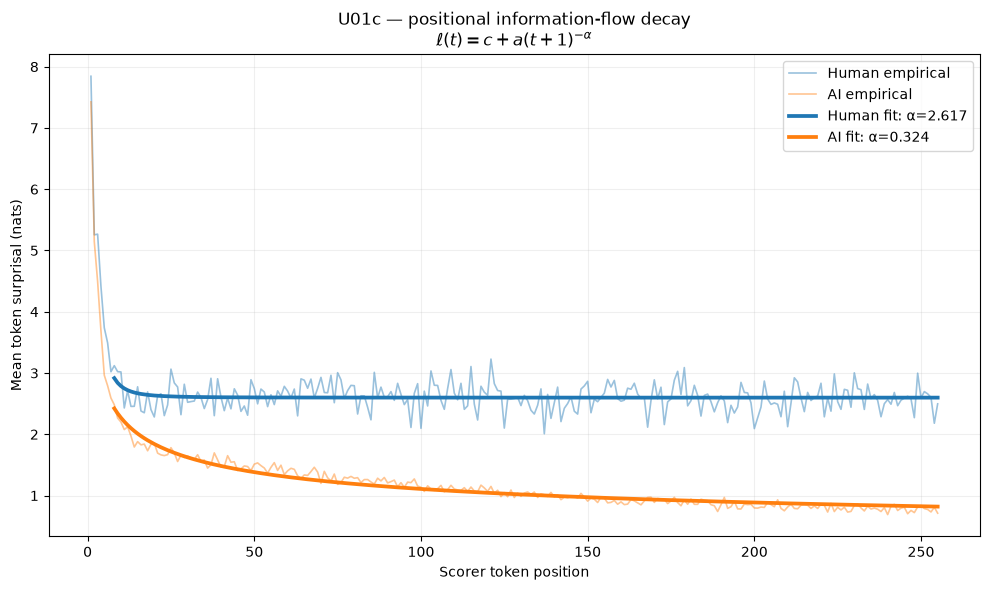


Saved U01c results to: ../results/causal/U01c_alpha_information_flow


In [2]:
# ============================================================
# Score positional surprisal and estimate alpha.
#
# IMPORTANT:
# - batch size is exactly 1
# - no generator is loaded
# - logits remain one-document-sized
# - scores checkpoint every completed document
# ============================================================

MAX_TOKENS = 256
FIT_MIN = 8
N_BOOT = 1000

LOSS_PATH = OUT / "positional_surprisal_256.parquet"

# ------------------------------------------------------------
# Tokenize + establish matched eligibility.
# ------------------------------------------------------------

token_cache = {}

for r in tqdm(
    raid[["source_id", "model", "generation"]].itertuples(index=False),
    total=len(raid),
    desc="Tokenizing",
):
    key = (str(r.source_id), str(r.model))

    token_cache[key] = stok(
        str(r.generation),
        add_special_tokens=False,
    )["input_ids"]


eligible_sources = []

for sid, g in raid.groupby("source_id"):
    sid = str(sid)
    present = set(g["model"].astype(str))

    if not set(ALL_MODELS).issubset(present):
        continue

    if not all(
        len(token_cache[(sid, m)]) >= MAX_TOKENS
        for m in ALL_MODELS
    ):
        continue

    eligible_sources.append(sid)


print("Fully matched >=256-token sources:", len(eligible_sources))
assert len(eligible_sources) > 0


jobs = [
    (sid, model)
    for sid in eligible_sources
    for model in ALL_MODELS
]


# ------------------------------------------------------------
# Resume checkpoint if present.
# ------------------------------------------------------------

if LOSS_PATH.exists():
    loss_df = pd.read_parquet(LOSS_PATH)

    done = set(
        zip(
            loss_df["source_id"].astype(str),
            loss_df["model"].astype(str),
        )
    )

    print("Resuming checkpoint:", len(done), "/", len(jobs))

else:
    loss_df = pd.DataFrame(
        columns=[
            "source_id",
            "model",
            "losses",
        ]
    )

    done = set()


# ------------------------------------------------------------
# Score one document at a time.
#
# We only need tokenwise CE.
# Keeping B=1 avoids the ~2.3 GiB temporary from the old run.
# ------------------------------------------------------------

for sid, model_name in tqdm(jobs, desc="Scoring surprisal"):

    if (sid, model_name) in done:
        continue

    ids = token_cache[(sid, model_name)][:MAX_TOKENS]

    x = torch.tensor(
        [ids],
        dtype=torch.long,
        device=device,
    )

    with torch.inference_mode():
        output = smodel(
            input_ids=x,
            use_cache=False,
        )

        logits = output.logits[:, :-1, :]
        targets = x[:, 1:]

        # B=1 means this temporary is small enough to safely use FP32 CE.
        ce = F.cross_entropy(
            logits.reshape(-1, logits.shape[-1]).float(),
            targets.reshape(-1),
            reduction="none",
        )

    losses_np = ce.detach().cpu().numpy().astype(np.float32)

    row = pd.DataFrame([{
        "source_id": sid,
        "model": model_name,
        "losses": losses_np.tolist(),
    }])

    loss_df = pd.concat(
        [loss_df, row],
        ignore_index=True,
    )

    loss_df.to_parquet(
        LOSS_PATH,
        index=False,
    )

    del x, output, logits, targets, ce, losses_np


print("Completed:", len(loss_df), "/", len(jobs))


# ------------------------------------------------------------
# Construct source × position matrices.
# ------------------------------------------------------------

loss_lookup = {
    (str(r.source_id), str(r.model)):
        np.asarray(r.losses, dtype=float)

    for r in loss_df.itertuples(index=False)
}

human_matrix = np.stack([
    loss_lookup[(sid, "human")]
    for sid in eligible_sources
])

machine_matrices = {
    m: np.stack([
        loss_lookup[(sid, m)]
        for sid in eligible_sources
    ])
    for m in AI_MODELS
}

# First average the six AI generators WITHIN each source.
ai_matrix = np.mean(
    np.stack(
        [machine_matrices[m] for m in AI_MODELS],
        axis=0,
    ),
    axis=0,
)

assert human_matrix.shape == ai_matrix.shape

N = len(eligible_sources)
positions = np.arange(1, MAX_TOKENS)


# ------------------------------------------------------------
# Fit ell(t) = c + a / (t+1)^alpha
# ------------------------------------------------------------

def decay_model(t, c, a, alpha):
    return c + a * np.power(t + 1.0, -alpha)


def fit_decay(matrix, fit_min=FIT_MIN):

    y_all = np.mean(matrix, axis=0)

    mask = positions >= fit_min

    x = positions[mask].astype(float)
    y = y_all[mask].astype(float)

    c0 = float(np.mean(y[-32:]))
    a0 = max(float(y[0] - c0), 0.1)

    pars, _ = curve_fit(
        decay_model,
        x,
        y,
        p0=[c0, a0, 0.5],
        bounds=(
            [0.0, 0.0, 0.001],
            [20.0, 100.0, 5.0],
        ),
        maxfev=50000,
    )

    pred = decay_model(x, *pars)

    ss_res = np.sum((y - pred) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)

    return {
        "c": float(pars[0]),
        "a": float(pars[1]),
        "alpha": float(pars[2]),
        "r2": float(1 - ss_res / ss_tot),
        "mean_loss": float(y_all.mean()),
    }


hf = fit_decay(human_matrix)
af = fit_decay(ai_matrix)

result = pd.DataFrame([
    {"condition": "HUMAN", **hf},
    {"condition": "AI_POOLED", **af},
]).set_index("condition")

display(result)

delta_alpha = af["alpha"] - hf["alpha"]

print()
print(f"alpha_H:  {hf['alpha']:.6f}")
print(f"alpha_AI: {af['alpha']:.6f}")
print(f"AI - H:   {delta_alpha:+.6f}")


# ------------------------------------------------------------
# Matched-source bootstrap.
# ------------------------------------------------------------

rng = np.random.default_rng(20260916)

boot = []

for _ in tqdm(range(N_BOOT), desc="Bootstrap"):

    idx = rng.integers(
        0,
        N,
        size=N,
    )

    try:
        bh = fit_decay(human_matrix[idx])["alpha"]
        ba = fit_decay(ai_matrix[idx])["alpha"]

        boot.append([
            bh,
            ba,
            ba - bh,
        ])

    except Exception:
        pass


boot = np.asarray(boot)

boot_summary = pd.DataFrame({
    "quantity": [
        "alpha_H",
        "alpha_AI",
        "alpha_AI_minus_H",
    ],
    "estimate": [
        hf["alpha"],
        af["alpha"],
        delta_alpha,
    ],
    "ci_low": [
        np.quantile(boot[:, 0], .025),
        np.quantile(boot[:, 1], .025),
        np.quantile(boot[:, 2], .025),
    ],
    "ci_high": [
        np.quantile(boot[:, 0], .975),
        np.quantile(boot[:, 1], .975),
        np.quantile(boot[:, 2], .975),
    ],
})

display(boot_summary)

print(
    "Bootstrap fraction alpha_AI > alpha_H:",
    f"{np.mean(boot[:, 2] > 0):.4f}"
)


# ------------------------------------------------------------
# Fit-range robustness.
# ------------------------------------------------------------

sens = []

for fit_min in [8, 16, 32, 64]:

    h = fit_decay(
        human_matrix,
        fit_min=fit_min,
    )

    a = fit_decay(
        ai_matrix,
        fit_min=fit_min,
    )

    sens.append({
        "fit_from": fit_min,
        "alpha_H": h["alpha"],
        "alpha_AI": a["alpha"],
        "AI_minus_H": a["alpha"] - h["alpha"],
        "R2_H": h["r2"],
        "R2_AI": a["r2"],
    })


sensitivity = pd.DataFrame(sens)

display(sensitivity)


# ------------------------------------------------------------
# Per-generator alpha.
# ------------------------------------------------------------

per_model = []

per_model.append({
    "model": "human",
    **fit_decay(human_matrix),
})

for m in AI_MODELS:
    per_model.append({
        "model": m,
        **fit_decay(machine_matrices[m]),
    })

per_model = pd.DataFrame(per_model).set_index("model")

display(
    per_model[
        ["alpha", "c", "a", "r2", "mean_loss"]
    ].sort_values("alpha")
)


# ------------------------------------------------------------
# Plot empirical mean + fitted curve.
# ------------------------------------------------------------

hmean = human_matrix.mean(axis=0)
amean = ai_matrix.mean(axis=0)

fig, ax = plt.subplots(figsize=(10, 6))

h_line, = ax.plot(
    positions,
    hmean,
    alpha=.45,
    linewidth=1.2,
    label="Human empirical",
)

a_line, = ax.plot(
    positions,
    amean,
    alpha=.45,
    linewidth=1.2,
    label="AI empirical",
)

xf = np.arange(FIT_MIN, MAX_TOKENS)

ax.plot(
    xf,
    decay_model(
        xf,
        hf["c"],
        hf["a"],
        hf["alpha"],
    ),
    linewidth=2.7,
    color=h_line.get_color(),
    label=f"Human fit: α={hf['alpha']:.3f}",
)

ax.plot(
    xf,
    decay_model(
        xf,
        af["c"],
        af["a"],
        af["alpha"],
    ),
    linewidth=2.7,
    color=a_line.get_color(),
    label=f"AI fit: α={af['alpha']:.3f}",
)

ax.set_xlabel("Scorer token position")
ax.set_ylabel("Mean token surprisal (nats)")
ax.set_title(
    "U01c — positional information-flow decay\n"
    r"$\ell(t)=c+a(t+1)^{-\alpha}$"
)

ax.grid(alpha=.2)
ax.legend()
fig.tight_layout()

fig.savefig(
    OUT / "alpha_human_vs_ai.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Save diagnostics.
# ------------------------------------------------------------

result.to_csv(
    OUT / "alpha_main_fit.csv"
)

boot_summary.to_csv(
    OUT / "alpha_bootstrap.csv",
    index=False,
)

sensitivity.to_csv(
    OUT / "alpha_fit_range_sensitivity.csv",
    index=False,
)

per_model.to_csv(
    OUT / "alpha_by_model.csv"
)

print("\nSaved U01c results to:", OUT)

,n,mean,median,q75,q90,q95,q99,std
condition,,,,,,,,
HUMAN,40800,2.664061,1.810134,4.017793,6.680948,8.321722,11.301883,2.738132
AI_POOLED,244800,1.209133,0.498500,1.675634,3.355828,4.846184,8.413426,1.772943


P_S_gt_tau           E_S_given_tail             \
condition  AI_POOLED     HUMAN      AI_POOLED      HUMAN   
tau                                                        
2           0.207467  0.471887       3.979933   4.874203   
3           0.119122  0.340931       5.120031   5.799878   
4           0.073725  0.251373       6.146581   6.626939   
5           0.046487  0.182598       7.135255   7.436096   
6           0.030025  0.129485       8.052734   8.241348   
8           0.012169  0.057892       9.774068   9.887285   
10          0.004179  0.021618      11.510392  11.598304   

          fraction_total_surprisal_from_tail            
condition                          AI_POOLED     HUMAN  
tau                                                     
2                                   0.682891  0.863372  
3                                   0.504417  0.742236  
4                                   0.374781  0.625298  
5                                   0.274326  0.509679  
6                                   0.199961  0.400566  
8                                   0.098369  0.214859  
10                                  0.039781  0.094115

top_share_of_total_surprisal           mean_after_removing_top  \
condition                       AI_POOLED     HUMAN               AI_POOLED   
top_fraction                                                                  
0.01                             0.083654  0.048013                1.119176   
0.05                             0.288628  0.190664                0.905414   
0.10                             0.454247  0.330398                0.733208   
0.20                             0.670337  0.541474                0.498258   

                        
condition        HUMAN  
top_fraction            
0.01          2.561769  
0.05          2.269602  
0.10          1.982067  
0.20          1.526928

probability_mass           contribution_to_mean          
condition            AI_POOLED     HUMAN            AI_POOLED     HUMAN
surprisal_bin                                                          
[0, 1)                0.627006  0.356887             0.143879  0.111876
[1, 2)                0.165527  0.171225             0.239547  0.252110
[10, inf)             0.004179  0.021618             0.048101  0.250728
[2, 3)                0.088346  0.130956             0.215799  0.322714
[3, 4)                0.045396  0.089559             0.156747  0.311530
[4, 6)                0.043701  0.121887             0.211380  0.598697
[6, 8)                0.017855  0.071593             0.122838  0.494737
[8, 10)               0.007990  0.036275             0.070841  0.321668

Sum of bin contributions to mean gap: 1.4549278139335815
Direct mean gap: 1.4549278139335817


condition,AI_POOLED,HUMAN,HUMAN_minus_AI
surprisal_bin,,,
"[0, 1)",0.143879,0.111876,-0.032003
"[1, 2)",0.239547,0.252110,0.012563
"[10, inf)",0.048101,0.250728,0.202627
"[2, 3)",0.215799,0.322714,0.106915
"[3, 4)",0.156747,0.311530,0.154782
"[4, 6)",0.211380,0.598697,0.387317
"[6, 8)",0.122838,0.494737,0.371899
"[8, 10)",0.070841,0.321668,0.250827


,tau,human_tail_rate,ai_tail_rate,H_minus_AI,ci_low,ci_high,bootstrap_P_H_gt_AI
0,2,0.471887,0.207467,0.264420,0.252855,0.275458,1.0
1,3,0.340931,0.119122,0.221810,0.211707,0.231606,1.0
2,4,0.251373,0.073725,0.177647,0.169493,0.185593,1.0
3,5,0.182598,0.046487,0.136111,0.129546,0.142656,1.0
4,6,0.129485,0.030025,0.099461,0.094277,0.104621,1.0
5,8,0.057892,0.012169,0.045723,0.042733,0.048693,1.0
6,10,0.021618,0.004179,0.017439,0.015662,0.019236,1.0


,position_bin,bin_midpoint,tau,human_tail_rate,ai_tail_rate
0,1-32,16.5,3,0.392188,0.270182
1,1-32,16.5,4,0.300586,0.191829
2,1-32,16.5,6,0.173047,0.098145
3,1-32,16.5,8,0.086133,0.048438
4,129-192,160.5,3,0.327539,0.086230
5,129-192,160.5,4,0.242383,0.050700
6,129-192,160.5,6,0.123047,0.018669
7,129-192,160.5,8,0.051953,0.006673
8,193-255,224.0,3,0.330754,0.076538
9,193-255,224.0,4,0.240774,0.046131


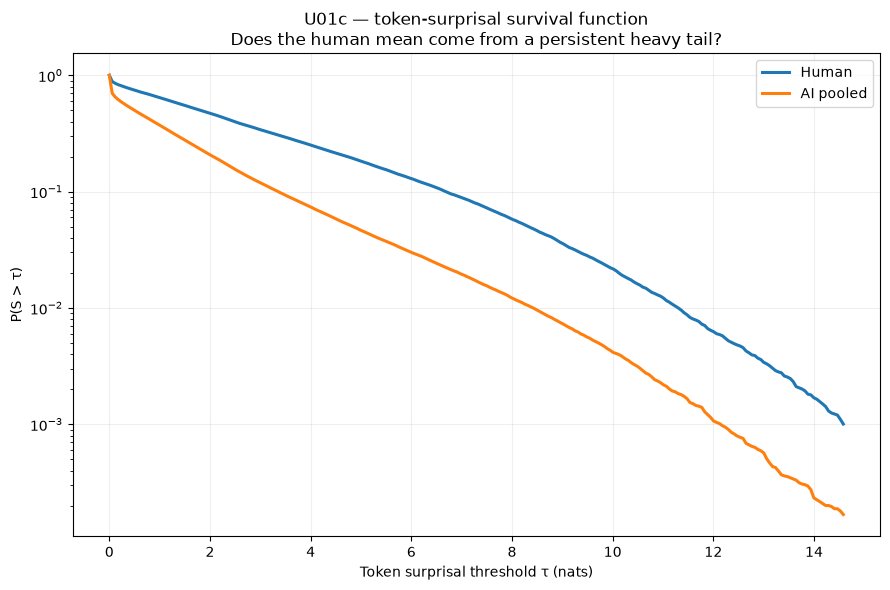

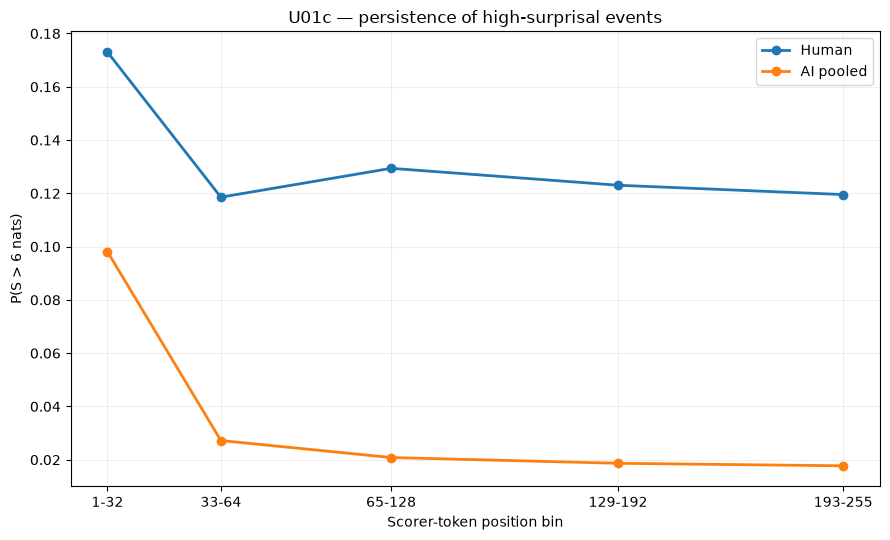

Saved token-tail diagnostics to: ../results/causal/U01c_alpha_information_flow


In [3]:
# ============================================================
# U01c — Token-surprisal tail decomposition
#
# Question:
# Is the higher human mean surprisal caused by:
#   (a) a broad upward shift in ordinary tokens, or
#   (b) a persistent minority of high-surprisal "information bursts"?
#
# No GPU work: uses positional_surprisal_256.parquet already scored.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

LOSS_PATH = OUT / "positional_surprisal_256.parquet"

if "loss_df" not in globals():
    loss_df = pd.read_parquet(LOSS_PATH)

assert len(loss_df) == len(eligible_sources) * len(ALL_MODELS)

loss_lookup = {
    (str(r.source_id), str(r.model)):
        np.asarray(r.losses, dtype=float)
    for r in loss_df.itertuples(index=False)
}

# Each source contributes equally.
human_by_source = {
    sid: loss_lookup[(sid, "human")]
    for sid in eligible_sources
}

ai_by_source = {
    sid: np.stack([
        loss_lookup[(sid, m)]
        for m in AI_MODELS
    ])
    for sid in eligible_sources
}

# Flatten only for descriptive distribution summaries.
# Human: N sources × 255 positions
# AI:    N sources × 6 models × 255 positions
human_tokens = np.concatenate(
    [human_by_source[sid] for sid in eligible_sources]
)

ai_tokens = np.concatenate(
    [ai_by_source[sid].reshape(-1) for sid in eligible_sources]
)


# ------------------------------------------------------------
# 1. Bulk distribution
# ------------------------------------------------------------

def distribution_summary(x):
    x = np.asarray(x, float)

    return {
        "n": len(x),
        "mean": x.mean(),
        "median": np.median(x),
        "q75": np.quantile(x, .75),
        "q90": np.quantile(x, .90),
        "q95": np.quantile(x, .95),
        "q99": np.quantile(x, .99),
        "std": x.std(),
    }


dist_summary = pd.DataFrame([
    {
        "condition": "HUMAN",
        **distribution_summary(human_tokens),
    },
    {
        "condition": "AI_POOLED",
        **distribution_summary(ai_tokens),
    },
]).set_index("condition")

display(dist_summary)


# ------------------------------------------------------------
# 2. Tail frequency, tail magnitude, and contribution to mean
#
# E[S] =
#   P(S<=tau) E[S|S<=tau]
# + P(S> tau) E[S|S> tau]
# ------------------------------------------------------------

TAIL_THRESHOLDS = [2, 3, 4, 5, 6, 8, 10]

tail_rows = []

for label, x in [
    ("HUMAN", human_tokens),
    ("AI_POOLED", ai_tokens),
]:
    x = np.asarray(x, float)
    total = x.sum()

    for tau in TAIL_THRESHOLDS:
        mask = x > tau

        tail_rows.append({
            "condition": label,
            "tau": tau,
            "P_S_gt_tau": mask.mean(),
            "E_S_given_tail": (
                x[mask].mean()
                if mask.any()
                else np.nan
            ),
            "tail_contribution_to_mean": np.mean(
                x * mask
            ),
            "fraction_total_surprisal_from_tail": (
                x[mask].sum() / total
                if total > 0
                else np.nan
            ),
        })

tail_table = pd.DataFrame(tail_rows)

display(
    tail_table.pivot(
        index="tau",
        columns="condition",
        values=[
            "P_S_gt_tau",
            "E_S_given_tail",
            "fraction_total_surprisal_from_tail",
        ],
    )
)


# ------------------------------------------------------------
# 3. How much total surprisal is concentrated in the top X%?
#
# Also compute mean after REMOVING that top X%.
# If the human-vs-AI mean gap collapses after trimming,
# the gap is primarily tail-driven.
# ------------------------------------------------------------

def top_fraction_stats(x, frac):
    x = np.asarray(x, float)

    n = len(x)
    k = max(1, int(np.ceil(frac * n)))

    cut = n - k
    part = np.partition(x, cut)

    lower = part[:cut]
    upper = part[cut:]

    return {
        "top_share_of_total_surprisal":
            upper.sum() / x.sum(),

        "mean_after_removing_top":
            lower.mean() if len(lower) else np.nan,
    }


top_rows = []

for label, x in [
    ("HUMAN", human_tokens),
    ("AI_POOLED", ai_tokens),
]:
    for frac in [.01, .05, .10, .20]:
        stats = top_fraction_stats(x, frac)

        top_rows.append({
            "condition": label,
            "top_fraction": frac,
            **stats,
        })

top_table = pd.DataFrame(top_rows)

display(
    top_table.pivot(
        index="top_fraction",
        columns="condition",
        values=[
            "top_share_of_total_surprisal",
            "mean_after_removing_top",
        ],
    )
)


# ------------------------------------------------------------
# 4. Exact mean decomposition by surprisal range.
#
# contribution_to_mean for a bin is:
#
#   E[S * 1{S in bin}]
#
# and all bins sum exactly to E[S].
# ------------------------------------------------------------

BIN_EDGES = [0, 1, 2, 3, 4, 6, 8, 10, np.inf]

bin_rows = []

for label, x in [
    ("HUMAN", human_tokens),
    ("AI_POOLED", ai_tokens),
]:
    x = np.asarray(x, float)

    for lo, hi in zip(BIN_EDGES[:-1], BIN_EDGES[1:]):
        mask = (x >= lo) & (x < hi)

        name = (
            f"[{lo:g}, {hi:g})"
            if np.isfinite(hi)
            else f"[{lo:g}, inf)"
        )

        bin_rows.append({
            "condition": label,
            "surprisal_bin": name,
            "probability_mass": mask.mean(),
            "mean_within_bin": (
                x[mask].mean()
                if mask.any()
                else np.nan
            ),
            "contribution_to_mean":
                np.mean(x * mask),
        })

bin_table = pd.DataFrame(bin_rows)

bin_compare = (
    bin_table.pivot(
        index="surprisal_bin",
        columns="condition",
        values=[
            "probability_mass",
            "contribution_to_mean",
        ],
    )
)

display(bin_compare)

gap_contrib = (
    bin_table.pivot(
        index="surprisal_bin",
        columns="condition",
        values="contribution_to_mean",
    )
)

gap_contrib["HUMAN_minus_AI"] = (
    gap_contrib["HUMAN"]
    - gap_contrib["AI_POOLED"]
)

print(
    "Sum of bin contributions to mean gap:",
    gap_contrib["HUMAN_minus_AI"].sum()
)

print(
    "Direct mean gap:",
    human_tokens.mean() - ai_tokens.mean()
)

display(gap_contrib)


# ------------------------------------------------------------
# 5. Matched-source inference for tail FREQUENCY.
#
# AI is averaged across the six generators within each source.
# This avoids treating hundreds of thousands of tokens as
# independent observations.
# ------------------------------------------------------------

source_tail_rows = []

for sid in eligible_sources:
    h = human_by_source[sid]
    a = ai_by_source[sid]

    for tau in TAIL_THRESHOLDS:
        source_tail_rows.append({
            "source_id": sid,
            "tau": tau,
            "human_tail_rate": float(
                np.mean(h > tau)
            ),
            "ai_tail_rate": float(
                np.mean(a > tau)
            ),
        })

source_tail = pd.DataFrame(source_tail_rows)

N_BOOT_TAIL = 5000
rng = np.random.default_rng(20260916)

boot_rows = []

for tau in TAIL_THRESHOLDS:
    z = source_tail[
        source_tail["tau"].eq(tau)
    ].copy()

    diff = (
        z["human_tail_rate"].to_numpy()
        - z["ai_tail_rate"].to_numpy()
    )

    n = len(diff)

    boot_idx = rng.integers(
        0,
        n,
        size=(N_BOOT_TAIL, n),
    )

    boot_means = diff[boot_idx].mean(axis=1)

    boot_rows.append({
        "tau": tau,
        "human_tail_rate":
            z["human_tail_rate"].mean(),

        "ai_tail_rate":
            z["ai_tail_rate"].mean(),

        "H_minus_AI":
            diff.mean(),

        "ci_low":
            np.quantile(boot_means, .025),

        "ci_high":
            np.quantile(boot_means, .975),

        "bootstrap_P_H_gt_AI":
            np.mean(boot_means > 0),
    })

tail_bootstrap = pd.DataFrame(boot_rows)

display(tail_bootstrap)


# ------------------------------------------------------------
# 6. Does the high-surprisal tail persist through the document?
# ------------------------------------------------------------

POSITION_BINS = [
    (1, 32),
    (33, 64),
    (65, 128),
    (129, 192),
    (193, 255),
]

POSITION_TAILS = [3, 4, 6, 8]

pos_rows = []

positions = np.arange(1, 256)

for sid in eligible_sources:
    h = human_by_source[sid]
    a = ai_by_source[sid]

    for lo, hi in POSITION_BINS:
        mask = (
            (positions >= lo)
            & (positions <= hi)
        )

        for tau in POSITION_TAILS:
            pos_rows.append({
                "source_id": sid,
                "position_bin": f"{lo}-{hi}",
                "bin_midpoint": (lo + hi) / 2,
                "tau": tau,

                "human_tail_rate":
                    float(np.mean(h[mask] > tau)),

                "ai_tail_rate":
                    float(np.mean(a[:, mask] > tau)),
            })

position_tail = pd.DataFrame(pos_rows)

position_summary = (
    position_tail
    .groupby(
        ["position_bin", "bin_midpoint", "tau"],
        as_index=False,
    )
    .agg(
        human_tail_rate=(
            "human_tail_rate",
            "mean",
        ),
        ai_tail_rate=(
            "ai_tail_rate",
            "mean",
        ),
    )
)

display(position_summary)


# ------------------------------------------------------------
# 7. Survival curve:
#
#     P(S > tau)
#
# This shows the entire right-tail geometry rather than only
# mean perplexity.
# ------------------------------------------------------------

xmax = min(
    20.0,
    max(
        np.quantile(human_tokens, .999),
        np.quantile(ai_tokens, .999),
    )
)

taus = np.linspace(0, xmax, 250)

human_survival = np.array([
    np.mean(human_tokens > tau)
    for tau in taus
])

ai_survival = np.array([
    np.mean(ai_tokens > tau)
    for tau in taus
])

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    taus,
    human_survival,
    linewidth=2.2,
    label="Human",
)

ax.plot(
    taus,
    ai_survival,
    linewidth=2.2,
    label="AI pooled",
)

ax.set_yscale("log")
ax.set_xlabel("Token surprisal threshold τ (nats)")
ax.set_ylabel("P(S > τ)")
ax.set_title(
    "U01c — token-surprisal survival function\n"
    "Does the human mean come from a persistent heavy tail?"
)
ax.grid(alpha=.2)
ax.legend()

fig.tight_layout()

fig.savefig(
    OUT / "token_surprisal_survival_human_ai.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# 8. Positional persistence of a strong tail.
# ------------------------------------------------------------

TAIL_PLOT = 6

z = (
    position_summary[
        position_summary["tau"].eq(TAIL_PLOT)
    ]
    .sort_values("bin_midpoint")
)

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(
    z["bin_midpoint"],
    z["human_tail_rate"],
    marker="o",
    linewidth=2,
    label="Human",
)

ax.plot(
    z["bin_midpoint"],
    z["ai_tail_rate"],
    marker="o",
    linewidth=2,
    label="AI pooled",
)

ax.set_xticks(
    z["bin_midpoint"],
    z["position_bin"],
)

ax.set_xlabel("Scorer-token position bin")
ax.set_ylabel(f"P(S > {TAIL_PLOT} nats)")
ax.set_title(
    "U01c — persistence of high-surprisal events"
)

ax.grid(alpha=.2)
ax.legend()
fig.tight_layout()

fig.savefig(
    OUT / f"tail_rate_gt_{TAIL_PLOT}_by_position.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

dist_summary.to_csv(
    OUT / "token_surprisal_distribution_summary.csv"
)

tail_table.to_csv(
    OUT / "token_surprisal_tail_summary.csv",
    index=False,
)

top_table.to_csv(
    OUT / "token_surprisal_top_fraction_summary.csv",
    index=False,
)

bin_table.to_csv(
    OUT / "token_surprisal_bin_decomposition.csv",
    index=False,
)

tail_bootstrap.to_csv(
    OUT / "token_surprisal_tail_bootstrap.csv",
    index=False,
)

position_summary.to_csv(
    OUT / "token_surprisal_tail_by_position.csv",
    index=False,
)

print("Saved token-tail diagnostics to:", OUT)

Building word/suffix events: 100%|█████████████████████████████████████████████████████████████████| 1120/1120 [00:01<00:00, 611.78it/s]


Token events: 285600 | Word events: 211933


n      mean    median       q90       q95  \
condition role                                                                
AI_POOLED nonword             43320  0.761763  0.314062  2.202117  2.706160   
          word_continuation   17876  0.852538  0.009912  3.139383  5.514785   
          word_initial       183604  1.349405  0.647965  3.691869  5.187870   
HUMAN     nonword              8205  1.396497  0.986639  3.264674  4.312938   
          word_continuation    4159  1.598112  0.158881  5.451219  7.365182   
          word_initial        28436  3.185711  2.398302  7.377727  8.887625   

                                   q99    P_gt_4    P_gt_6    P_gt_8  
condition role                                                        
AI_POOLED nonword             4.719466  0.016828  0.004224  0.001477  
          word_continuation   9.454801  0.080611  0.043075  0.019467  
          word_initial        8.665547  0.086480  0.034841  0.013981  
HUMAN     nonword             6.978043  0.061426  0.019378  0.005484  
          word_continuation  11.081626  0.157009  0.083914  0.037749  
          word_initial       11.696589  0.319982  0.167921  0.075960

token_fraction           mean_surprisal            \
condition              AI_POOLED     HUMAN      AI_POOLED     HUMAN   
role                                                                  
nonword                 0.176961  0.201103       0.761763  1.396497   
word_continuation       0.073023  0.101936       0.852538  1.598112   
word_initial            0.750016  0.696961       1.349405  3.185711   

                  fraction_total_surprisal            
condition                        AI_POOLED     HUMAN  
role                                                  
nonword                           0.111487  0.105418  
word_continuation                 0.051487  0.061149  
word_initial                      0.837026  0.833433

,n,mean,median,q75,q90,q95,q99,mean_scorer_tokens_per_word,mean_subtoken_surprisal
condition,,,,,,,,,
AI_POOLED,183511,1.408368,0.655473,1.907599,3.763067,5.349564,9.643548,1.093019,1.277150
HUMAN,28422,3.392348,2.426158,4.933458,7.815888,9.793197,14.639088,1.141616,2.988214


P_word_S_gt_tau           E_word_S_given_tail             \
condition       AI_POOLED     HUMAN           AI_POOLED      HUMAN   
tau                                                                  
3                0.142809  0.428999            5.415406   6.317882   
4                0.089891  0.326261            6.569659   7.209708   
6                0.038864  0.180283            8.855490   9.066140   
8                0.018473  0.093976           11.047191  11.052939   
10               0.008588  0.046197           13.533016  13.282400   
12               0.004054  0.022271           16.538626  15.891520   

          fraction_word_surprisal_from_tail            
condition                         AI_POOLED     HUMAN  
tau                                                    
3                                  0.549123  0.798964  
4                                  0.419318  0.693399  
6                                  0.244369  0.481811  
8                                  0.144902  0.306194  
10                                 0.082523  0.180878  
12                                 0.047610  0.104331

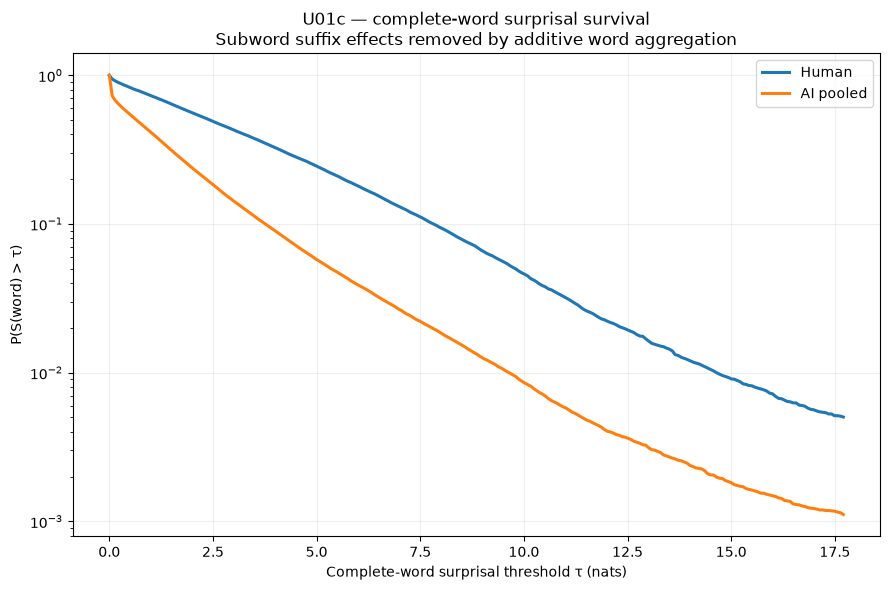

Saved lexical-role and word-level diagnostics to: ../results/causal/U01c_alpha_information_flow


In [4]:
# ============================================================
# U01c — Subword-role + word-level surprisal analysis
#
# Motivation:
# A high token-level human mean might be misleading if most
# tokens remain very predictable and only occasional lexical
# events carry large surprisal.
#
# We therefore distinguish:
#
#   word_initial
#   word_continuation   <- BPE/subword suffixes live here
#   nonword
#
# and then SUM scorer-token surprisals within complete words:
#
#   S(word) = Σ S(token_i)
#
# No GPU work.
# ============================================================

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

assert getattr(stok, "is_fast", False), \
    "Need a fast tokenizer for offset mappings."

WORD_RE = re.compile(
    r"[^\W\d_]+(?:['’\-][^\W\d_]+)*",
    flags=re.UNICODE,
)

# Original text lookup.
text_lookup = {}

for r in raid[
    ["source_id", "model", "generation"]
].itertuples(index=False):

    key = (
        str(r.source_id),
        str(r.model),
    )

    if key in loss_lookup:
        text_lookup[key] = str(r.generation)

assert len(text_lookup) == len(loss_lookup)


def token_word_events(text, losses):
    """
    Returns:
      token_events:
          one row per scored token with lexical role

      word_events:
          one row per COMPLETE word fully covered by scored
          token positions 1..255
    """

    enc = stok(
        text,
        add_special_tokens=False,
        return_offsets_mapping=True,
    )

    offsets = enc["offset_mapping"][:256]

    losses = np.asarray(losses, float)

    assert len(offsets) >= 256
    assert len(losses) == 255

    words = [
        {
            "start": m.start(),
            "end": m.end(),
            "text": m.group(0),
        }
        for m in WORD_RE.finditer(text)
    ]

    # Map each tokenizer token to at most one alphabetic word.
    token_to_word = {}

    wi = 0

    for ti, (a, b) in enumerate(offsets):
        if b <= a:
            continue

        while (
            wi < len(words)
            and words[wi]["end"] <= a
        ):
            wi += 1

        j = wi

        while (
            j < len(words)
            and words[j]["start"] < b
        ):
            w = words[j]

            if (
                w["end"] > a
                and w["start"] < b
            ):
                token_to_word[ti] = j
                break

            j += 1

    # ---------------------------------------------
    # Token lexical roles.
    # ---------------------------------------------

    token_events = []

    for ti in range(1, 256):
        loss = float(losses[ti - 1])

        if ti not in token_to_word:
            role = "nonword"

        else:
            j = token_to_word[ti]
            w = words[j]

            a, b = offsets[ti]

            # Initial subtoken contains the beginning of the word.
            if a <= w["start"] < b:
                role = "word_initial"
            else:
                role = "word_continuation"

        token_events.append({
            "token_position": ti,
            "surprisal": loss,
            "role": role,
        })

    # ---------------------------------------------
    # Complete-word surprisal.
    #
    # Skip:
    #   - word touched by token 0, whose surprisal we do not have
    #   - word extending beyond token 255 coverage
    # ---------------------------------------------

    tokens_by_word = {}

    for ti, j in token_to_word.items():
        tokens_by_word.setdefault(j, []).append(ti)

    covered_end = offsets[255][1]

    word_events = []

    for j, token_ids in tokens_by_word.items():
        w = words[j]

        token_ids = sorted(token_ids)

        if 0 in token_ids:
            continue

        if w["end"] > covered_end:
            continue

        scored_ids = [
            ti
            for ti in token_ids
            if 1 <= ti <= 255
        ]

        if not scored_ids:
            continue

        word_losses = np.array([
            losses[ti - 1]
            for ti in scored_ids
        ])

        word_events.append({
            "word": w["text"],
            "word_start": w["start"],
            "n_scorer_tokens": len(scored_ids),

            # Actual additive code length of the word.
            "word_surprisal":
                float(word_losses.sum()),

            # Controls for tokenizer fragmentation.
            "mean_subtoken_surprisal":
                float(word_losses.mean()),

            "max_subtoken_surprisal":
                float(word_losses.max()),
        })

    return token_events, word_events


# ------------------------------------------------------------
# Extract events for every matched source/model.
# ------------------------------------------------------------

token_event_rows = []
word_event_rows = []

jobs = [
    (sid, model)
    for sid in eligible_sources
    for model in ALL_MODELS
]

for sid, model_name in tqdm(
    jobs,
    desc="Building word/suffix events",
):
    text = text_lookup[(sid, model_name)]
    losses = loss_lookup[(sid, model_name)]

    token_events, word_events = token_word_events(
        text,
        losses,
    )

    condition = (
        "HUMAN"
        if model_name == "human"
        else "AI_POOLED"
    )

    for r in token_events:
        token_event_rows.append({
            "source_id": sid,
            "model": model_name,
            "condition": condition,
            **r,
        })

    for r in word_events:
        word_event_rows.append({
            "source_id": sid,
            "model": model_name,
            "condition": condition,
            **r,
        })

token_events = pd.DataFrame(token_event_rows)
word_events = pd.DataFrame(word_event_rows)

print(
    "Token events:",
    len(token_events),
    "| Word events:",
    len(word_events),
)


# ------------------------------------------------------------
# 1. Role decomposition.
#
# This directly tests:
# "Are suffix/continuation tokens indeed very unsurprising?"
# ------------------------------------------------------------

def q90(x):
    return np.quantile(x, .90)

def q95(x):
    return np.quantile(x, .95)

def q99(x):
    return np.quantile(x, .99)

role_summary = (
    token_events
    .groupby(
        ["condition", "role"]
    )
    .agg(
        n=("surprisal", "size"),
        mean=("surprisal", "mean"),
        median=("surprisal", "median"),
        q90=("surprisal", q90),
        q95=("surprisal", q95),
        q99=("surprisal", q99),
        P_gt_4=(
            "surprisal",
            lambda x: np.mean(x > 4),
        ),
        P_gt_6=(
            "surprisal",
            lambda x: np.mean(x > 6),
        ),
        P_gt_8=(
            "surprisal",
            lambda x: np.mean(x > 8),
        ),
    )
)

display(role_summary)


# ------------------------------------------------------------
# 2. How much of total code length comes from each role?
# ------------------------------------------------------------

role_contrib_rows = []

for condition, g in token_events.groupby("condition"):
    total_s = g["surprisal"].sum()
    total_n = len(g)

    for role, r in g.groupby("role"):
        role_contrib_rows.append({
            "condition": condition,
            "role": role,

            "token_fraction":
                len(r) / total_n,

            "mean_surprisal":
                r["surprisal"].mean(),

            "fraction_total_surprisal":
                r["surprisal"].sum() / total_s,
        })

role_contrib = pd.DataFrame(role_contrib_rows)

display(
    role_contrib.pivot(
        index="role",
        columns="condition",
        values=[
            "token_fraction",
            "mean_surprisal",
            "fraction_total_surprisal",
        ],
    )
)


# ------------------------------------------------------------
# 3. Word-level distributions.
#
# If human information bursts are genuinely lexical rather than
# merely BPE artifacts, they should remain visible after summing
# subtoken surprisal within complete words.
# ------------------------------------------------------------

def word_distribution_summary(x):
    x = np.asarray(x, float)

    return {
        "n": len(x),
        "mean": x.mean(),
        "median": np.median(x),
        "q75": np.quantile(x, .75),
        "q90": np.quantile(x, .90),
        "q95": np.quantile(x, .95),
        "q99": np.quantile(x, .99),
    }


word_summary_rows = []

for condition, g in word_events.groupby("condition"):
    word_summary_rows.append({
        "condition": condition,
        **word_distribution_summary(
            g["word_surprisal"]
        ),
        "mean_scorer_tokens_per_word":
            g["n_scorer_tokens"].mean(),

        "mean_subtoken_surprisal":
            g["mean_subtoken_surprisal"].mean(),
    })

word_summary = (
    pd.DataFrame(word_summary_rows)
    .set_index("condition")
)

display(word_summary)


# ------------------------------------------------------------
# 4. Word-level tails.
#
# This is especially relevant to the 0.05 word-path guard,
# although Qwen scorer surprisal is not numerically identical
# to generator word-path surprisal.
# ------------------------------------------------------------

WORD_THRESHOLDS = [3, 4, 6, 8, 10, 12]

word_tail_rows = []

for condition, g in word_events.groupby("condition"):
    x = g["word_surprisal"].to_numpy(float)

    for tau in WORD_THRESHOLDS:
        mask = x > tau

        word_tail_rows.append({
            "condition": condition,
            "tau": tau,

            "P_word_S_gt_tau":
                mask.mean(),

            "E_word_S_given_tail":
                (
                    x[mask].mean()
                    if mask.any()
                    else np.nan
                ),

            "fraction_word_surprisal_from_tail":
                (
                    x[mask].sum() / x.sum()
                    if x.sum() > 0
                    else np.nan
                ),
        })

word_tail = pd.DataFrame(word_tail_rows)

display(
    word_tail.pivot(
        index="tau",
        columns="condition",
        values=[
            "P_word_S_gt_tau",
            "E_word_S_given_tail",
            "fraction_word_surprisal_from_tail",
        ],
    )
)


# ------------------------------------------------------------
# 5. Word-surprisal survival curves.
# ------------------------------------------------------------

human_word_s = (
    word_events.loc[
        word_events["condition"].eq("HUMAN"),
        "word_surprisal",
    ]
    .to_numpy(float)
)

ai_word_s = (
    word_events.loc[
        word_events["condition"].eq("AI_POOLED"),
        "word_surprisal",
    ]
    .to_numpy(float)
)

xmax_word = min(
    30.0,
    max(
        np.quantile(human_word_s, .995),
        np.quantile(ai_word_s, .995),
    )
)

taus_word = np.linspace(
    0,
    xmax_word,
    250,
)

human_word_survival = np.array([
    np.mean(human_word_s > tau)
    for tau in taus_word
])

ai_word_survival = np.array([
    np.mean(ai_word_s > tau)
    for tau in taus_word
])

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    taus_word,
    human_word_survival,
    linewidth=2.2,
    label="Human",
)

ax.plot(
    taus_word,
    ai_word_survival,
    linewidth=2.2,
    label="AI pooled",
)

ax.set_yscale("log")
ax.set_xlabel("Complete-word surprisal threshold τ (nats)")
ax.set_ylabel("P(S(word) > τ)")
ax.set_title(
    "U01c — complete-word surprisal survival\n"
    "Subword suffix effects removed by additive word aggregation"
)

ax.grid(alpha=.2)
ax.legend()
fig.tight_layout()

fig.savefig(
    OUT / "word_surprisal_survival_human_ai.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

token_events.to_parquet(
    OUT / "token_lexical_role_events.parquet",
    index=False,
)

word_events.to_parquet(
    OUT / "word_surprisal_events.parquet",
    index=False,
)

role_summary.to_csv(
    OUT / "token_role_surprisal_summary.csv"
)

role_contrib.to_csv(
    OUT / "token_role_surprisal_contribution.csv",
    index=False,
)

word_summary.to_csv(
    OUT / "word_surprisal_summary.csv"
)

word_tail.to_csv(
    OUT / "word_surprisal_tail_summary.csv",
    index=False,
)

print("Saved lexical-role and word-level diagnostics to:", OUT)

Matched OG/FULL cases: 20


,case_id,domain
0,gate_0090,abstracts
1,gate_0070,books
2,gate_0017,news
3,gate_0085,recipes
4,gate_0038,reddit
5,gate_0039,wiki
6,gate_0069,abstracts
7,gate_0035,books
8,gate_0003,news
9,gate_0025,recipes


Scoring OG vs FULL: 100%|███████████████████████████████████████████████████████████████████████████████| 40/40 [00:01<00:00, 35.26it/s]


Length comparison:


,case_id,OG_total_tokens,FULL_total_tokens,FULL_minus_OG_tokens,matched_scored_positions
0,gate_0090,229,207,-22,206
1,gate_0070,267,374,107,255
2,gate_0017,394,473,79,255
3,gate_0085,299,650,351,255
4,gate_0038,142,142,0,141
5,gate_0039,207,516,309,206
6,gate_0069,129,215,86,128
7,gate_0035,265,370,105,255
8,gate_0003,427,442,15,255
9,gate_0025,341,596,255,255


...

condition,FULL,OG,FULL_minus_OG
surprisal_bin,,,
"[0, 1)",0.139867,0.142785,-0.002918
"[1, 2)",0.272937,0.255538,0.017399
"[10, inf)",0.094944,0.129482,-0.034539
"[2, 3)",0.274071,0.285228,-0.011157
"[3, 4)",0.262265,0.237673,0.024591
"[4, 6)",0.421634,0.426730,-0.005096
"[6, 8)",0.262445,0.298085,-0.035640
"[8, 10)",0.129950,0.159513,-0.029563


Direct FULL - OG mean gap: -0.07692187639515624
Sum of bin contributions: -0.07692187639515602

Paired innovation-rate shift:


,tau,OG_tail_rate,FULL_tail_rate,FULL_minus_OG,ci_low,ci_high,bootstrap_P_FULL_gt_OG
0,2,0.340929,0.335360,-0.005569,-0.045801,0.029046,0.4070
1,3,0.225144,0.222327,-0.002817,-0.039160,0.028694,0.4456
2,4,0.156302,0.146711,-0.009591,-0.039436,0.014978,0.2720
3,5,0.110045,0.094685,-0.015361,-0.040501,0.004687,0.0694
4,6,0.070840,0.059712,-0.011128,-0.032621,0.004826,0.1066
5,8,0.028246,0.022288,-0.005959,-0.016248,0.001334,0.0706
6,10,0.010535,0.007971,-0.002564,-0.008241,0.001915,0.1602



Tail persistence by position:


,position_bin,bin_midpoint,tau,n_cases,OG_tail_rate,FULL_tail_rate,FULL_minus_OG
0,1-32,16.5,3,20,0.340625,0.362500,0.021875
1,1-32,16.5,4,20,0.250000,0.284375,0.034375
2,1-32,16.5,6,20,0.146875,0.154688,0.007812
3,1-32,16.5,8,20,0.070312,0.079687,0.009375
4,129-192,160.5,3,17,0.216912,0.197610,-0.019301
5,129-192,160.5,4,17,0.152574,0.130515,-0.022059
6,129-192,160.5,6,17,0.062500,0.046875,-0.015625
7,129-192,160.5,8,17,0.023897,0.011949,-0.011949
8,193-255,224.0,3,13,0.194139,0.163614,-0.030525
9,193-255,224.0,4,13,0.137973,0.107448,-0.030525


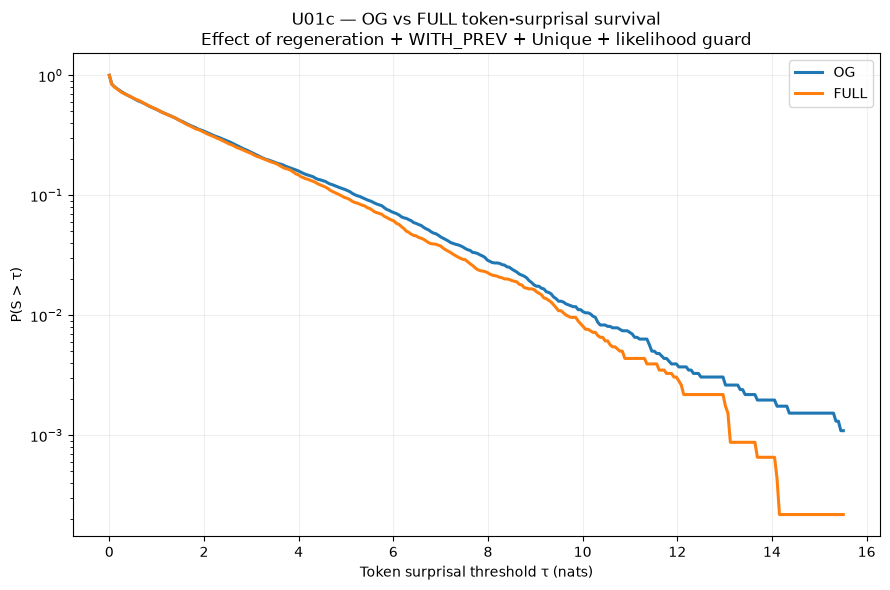

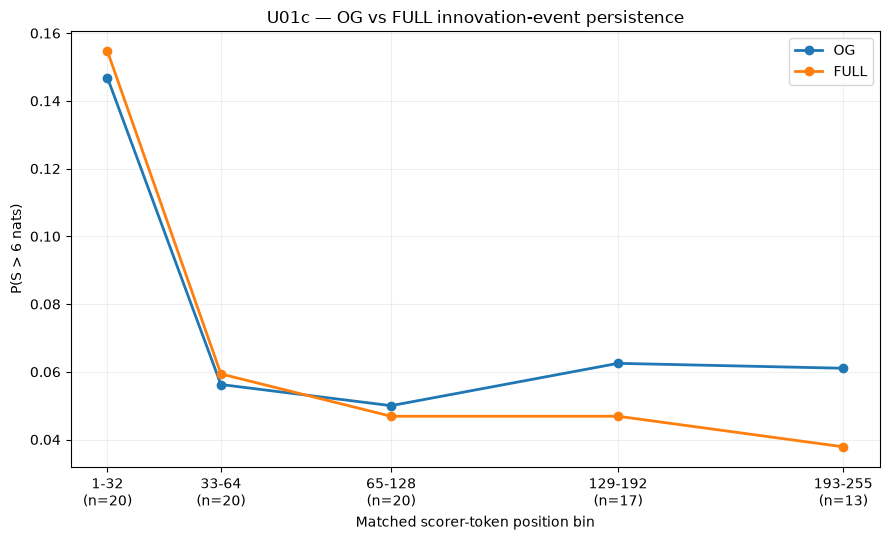


Saved OG/FULL token-flow comparison to: ../results/causal/U01c_alpha_information_flow


In [5]:
# ============================================================
# U01c — OG vs FULL surprisal-flow comparison
#
# FULL = U01b FULL-history arm:
#        Llama-3.2-3B-Instruct + WITH_PREV + Unique controller
#        + canonical 0.05 word-path likelihood guard.
#
# Goal:
# Measure what the complete regeneration stack does to:
#   - mean / median surprisal
#   - moderate/high-surprisal event frequency
#   - event magnitude conditional on occurring
#   - positional persistence of those events
#   - output length
#
# IMPORTANT:
# For distribution comparisons, each case is truncated to the
# SAME scorer-token prefix length:
#
#   min(len(OG), len(FULL), 256)
#
# so longer FULL outputs do not automatically contribute more
# late low-surprisal tokens.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from IPython.display import display

assert "stok" in globals() and "smodel" in globals()

U01B = ROOT / "results/causal/U01b_joint_unique_temporal_withprev"
U01 = ROOT / "results/causal/U01_temporal_method_selection"

GEN_PATH = U01B / "joint_generations.parquet"
PAIR_PATH = ROOT / "results/causal/C02d2_fz118_ghostbuster_raid/paired_corpus.parquet"
COHORT_PATH = U01 / "cohort20.csv"

assert GEN_PATH.exists(), GEN_PATH
assert PAIR_PATH.exists(), PAIR_PATH
assert COHORT_PATH.exists(), COHORT_PATH

MAX_COMPARE_TOKENS = 256
SCORE_CACHE = OUT / "OG_FULL_positional_surprisal.parquet"


# ------------------------------------------------------------
# 1. Reconstruct the exact OG texts used by U01b.
# ------------------------------------------------------------

gen_b = pd.read_parquet(GEN_PATH).copy()

full = (
    gen_b.loc[
        gen_b["method"].eq("FULL")
        & ~gen_b.get(
            "controller_status",
            pd.Series("", index=gen_b.index)
        ).astype(str).eq("failed_exception")
    ]
    .copy()
)

assert full["case_id"].is_unique

cohort_b = pd.read_csv(
    COHORT_PATH,
    keep_default_na=False,
)

paired_b = pd.read_parquet(PAIR_PATH).copy()


def _raw_id(x):
    x = str(x)
    return (
        x.split("ai__raid:", 1)[1]
        if x.startswith("ai__raid:")
        else x
    )


paired_b["raw_id"] = (
    paired_b["source_id"]
    .astype(str)
    .map(_raw_id)
)

exact = (
    paired_b
    .drop_duplicates("source_id")
    .set_index("source_id")["text"]
    .to_dict()
)

rawmap = (
    paired_b
    .drop_duplicates("raw_id")
    .set_index("raw_id")["text"]
    .to_dict()
)

cohort_b["raw_id"] = (
    cohort_b["source_id"]
    .astype(str)
    .map(_raw_id)
)

cohort_b["OG"] = (
    cohort_b["source_id"]
    .astype(str)
    .map(exact)
)

miss = cohort_b["OG"].isna()

cohort_b.loc[miss, "OG"] = (
    cohort_b.loc[miss, "raw_id"]
    .map(rawmap)
)

assert cohort_b["OG"].notna().all()


panel = (
    cohort_b[
        ["case_id", "source_id", "domain", "OG"]
    ]
    .merge(
        full[
            [
                "case_id",
                "generated_text",
            ]
        ],
        on="case_id",
        how="inner",
        validate="one_to_one",
    )
    .rename(
        columns={
            "generated_text": "FULL",
        }
    )
)

assert len(panel) > 0

print("Matched OG/FULL cases:", len(panel))
display(panel[["case_id", "domain"]])


# ------------------------------------------------------------
# 2. Score token surprisal, B=1.
# ------------------------------------------------------------

if SCORE_CACHE.exists():
    of_scores = pd.read_parquet(SCORE_CACHE)

    done = set(
        zip(
            of_scores["case_id"],
            of_scores["condition"],
        )
    )

    print(
        "Resuming score cache:",
        len(done),
        "/",
        2 * len(panel),
    )

else:
    of_scores = pd.DataFrame(
        columns=[
            "case_id",
            "condition",
            "n_scorer_tokens",
            "losses",
        ]
    )

    done = set()


jobs = []

for r in panel.itertuples(index=False):
    jobs.append(
        (
            r.case_id,
            "OG",
            str(r.OG),
        )
    )

    jobs.append(
        (
            r.case_id,
            "FULL",
            str(r.FULL),
        )
    )


for case_id, condition, text in tqdm(
    jobs,
    desc="Scoring OG vs FULL",
):

    if (case_id, condition) in done:
        continue

    ids_all = stok(
        text,
        add_special_tokens=False,
    )["input_ids"]

    n_total = len(ids_all)

    ids = ids_all[:MAX_COMPARE_TOKENS]

    assert len(ids) >= 2, (
        case_id,
        condition,
        len(ids),
    )

    x = torch.tensor(
        [ids],
        dtype=torch.long,
        device=device,
    )

    with torch.inference_mode():
        output = smodel(
            input_ids=x,
            use_cache=False,
        )

        logits = output.logits[:, :-1, :]
        targets = x[:, 1:]

        ce = F.cross_entropy(
            logits.reshape(
                -1,
                logits.shape[-1],
            ).float(),
            targets.reshape(-1),
            reduction="none",
        )

    losses_np = (
        ce.detach()
        .cpu()
        .numpy()
        .astype(np.float32)
    )

    of_scores = pd.concat(
        [
            of_scores,
            pd.DataFrame([{
                "case_id": case_id,
                "condition": condition,
                "n_scorer_tokens": n_total,
                "losses": losses_np.tolist(),
            }]),
        ],
        ignore_index=True,
    )

    of_scores.to_parquet(
        SCORE_CACHE,
        index=False,
    )

    del x, output, logits, targets, ce


# ------------------------------------------------------------
# 3. Build EXACT paired-prefix loss vectors.
# ------------------------------------------------------------

of_lookup = {
    (
        str(r.case_id),
        str(r.condition),
    ):
    np.asarray(
        r.losses,
        dtype=float,
    )
    for r in of_scores.itertuples(index=False)
}

length_lookup = {
    (
        str(r.case_id),
        str(r.condition),
    ):
    int(r.n_scorer_tokens)
    for r in of_scores.itertuples(index=False)
}


paired_losses = {}

pair_meta = []

for cid in panel["case_id"].astype(str):

    og = of_lookup[(cid, "OG")]
    fu = of_lookup[(cid, "FULL")]

    # Same predicted-token support.
    m = min(
        len(og),
        len(fu),
        MAX_COMPARE_TOKENS - 1,
    )

    assert m > 0

    paired_losses[(cid, "OG")] = og[:m]
    paired_losses[(cid, "FULL")] = fu[:m]

    pair_meta.append({
        "case_id": cid,
        "OG_total_tokens":
            length_lookup[(cid, "OG")],

        "FULL_total_tokens":
            length_lookup[(cid, "FULL")],

        "FULL_minus_OG_tokens":
            (
                length_lookup[(cid, "FULL")]
                - length_lookup[(cid, "OG")]
            ),

        "matched_scored_positions": m,
    })

pair_meta = pd.DataFrame(pair_meta)

print("\nLength comparison:")
display(pair_meta)

print("\nMean lengths:")
display(
    pair_meta[
        [
            "OG_total_tokens",
            "FULL_total_tokens",
            "FULL_minus_OG_tokens",
        ]
    ].mean()
)


# ------------------------------------------------------------
# 4. Distribution summaries.
# ------------------------------------------------------------

og_tokens = np.concatenate([
    paired_losses[(cid, "OG")]
    for cid in panel["case_id"].astype(str)
])

full_tokens = np.concatenate([
    paired_losses[(cid, "FULL")]
    for cid in panel["case_id"].astype(str)
])


def _dist_summary(x):
    x = np.asarray(x, float)

    return {
        "n": len(x),
        "mean": np.mean(x),
        "median": np.median(x),
        "q75": np.quantile(x, .75),
        "q90": np.quantile(x, .90),
        "q95": np.quantile(x, .95),
        "q99": np.quantile(x, .99),
        "std": np.std(x),
    }


of_dist = pd.DataFrame([
    {
        "condition": "OG",
        **_dist_summary(og_tokens),
    },
    {
        "condition": "FULL",
        **_dist_summary(full_tokens),
    },
]).set_index("condition")

print("\nMatched-prefix token-surprisal distribution:")
display(of_dist)


# ------------------------------------------------------------
# 5. Tail frequency vs tail magnitude.
# ------------------------------------------------------------

TAILS = [2, 3, 4, 5, 6, 8, 10]

tail_rows = []

for label, x in [
    ("OG", og_tokens),
    ("FULL", full_tokens),
]:
    x = np.asarray(x, float)

    for tau in TAILS:
        mask = x > tau

        tail_rows.append({
            "condition": label,
            "tau": tau,

            "P_S_gt_tau":
                float(mask.mean()),

            "E_S_given_tail":
                float(
                    x[mask].mean()
                    if mask.any()
                    else np.nan
                ),

            "fraction_total_surprisal_from_tail":
                float(
                    x[mask].sum() / x.sum()
                    if x.sum() > 0
                    else np.nan
                ),
        })

of_tail = pd.DataFrame(tail_rows)

print("\nTail frequency / magnitude:")
display(
    of_tail.pivot(
        index="tau",
        columns="condition",
        values=[
            "P_S_gt_tau",
            "E_S_given_tail",
            "fraction_total_surprisal_from_tail",
        ],
    )
)


# ------------------------------------------------------------
# 6. Exact mean-gap decomposition.
# ------------------------------------------------------------

BIN_EDGES = [
    0, 1, 2, 3, 4, 6, 8, 10, np.inf
]

bin_rows = []

for label, x in [
    ("OG", og_tokens),
    ("FULL", full_tokens),
]:

    for lo, hi in zip(
        BIN_EDGES[:-1],
        BIN_EDGES[1:],
    ):

        mask = (
            (x >= lo)
            & (x < hi)
        )

        name = (
            f"[{lo:g}, {hi:g})"
            if np.isfinite(hi)
            else f"[{lo:g}, inf)"
        )

        bin_rows.append({
            "condition": label,
            "surprisal_bin": name,

            "probability_mass":
                float(mask.mean()),

            "contribution_to_mean":
                float(
                    np.mean(
                        x * mask
                    )
                ),
        })

of_bins = pd.DataFrame(bin_rows)

gap = (
    of_bins
    .pivot(
        index="surprisal_bin",
        columns="condition",
        values="contribution_to_mean",
    )
)

gap["FULL_minus_OG"] = (
    gap["FULL"]
    - gap["OG"]
)

print("\nWhere does FULL change mean surprisal?")
display(gap)

print(
    "Direct FULL - OG mean gap:",
    full_tokens.mean()
    - og_tokens.mean()
)

print(
    "Sum of bin contributions:",
    gap["FULL_minus_OG"].sum()
)


# ------------------------------------------------------------
# 7. Paired CASE-LEVEL inference for innovation frequency.
#
# This is the important inferential version:
# every case gets equal weight.
# ------------------------------------------------------------

source_tail_rows = []

for cid in panel["case_id"].astype(str):

    og = paired_losses[(cid, "OG")]
    fu = paired_losses[(cid, "FULL")]

    for tau in TAILS:
        source_tail_rows.append({
            "case_id": cid,
            "tau": tau,

            "OG_tail_rate":
                float(np.mean(og > tau)),

            "FULL_tail_rate":
                float(np.mean(fu > tau)),
        })

of_source_tail = pd.DataFrame(
    source_tail_rows
)

rng = np.random.default_rng(20260916)

N_BOOT = 5000
boot_rows = []

for tau in TAILS:

    z = of_source_tail[
        of_source_tail["tau"].eq(tau)
    ]

    diff = (
        z["FULL_tail_rate"].to_numpy()
        - z["OG_tail_rate"].to_numpy()
    )

    n = len(diff)

    idx = rng.integers(
        0,
        n,
        size=(N_BOOT, n),
    )

    bm = diff[idx].mean(axis=1)

    boot_rows.append({
        "tau": tau,

        "OG_tail_rate":
            z["OG_tail_rate"].mean(),

        "FULL_tail_rate":
            z["FULL_tail_rate"].mean(),

        "FULL_minus_OG":
            diff.mean(),

        "ci_low":
            np.quantile(bm, .025),

        "ci_high":
            np.quantile(bm, .975),

        "bootstrap_P_FULL_gt_OG":
            np.mean(bm > 0),
    })

of_tail_boot = pd.DataFrame(
    boot_rows
)

print("\nPaired innovation-rate shift:")
display(of_tail_boot)


# ------------------------------------------------------------
# 8. Positional persistence.
#
# Only a case with BOTH OG and FULL reaching the whole bin
# contributes to that bin.
# ------------------------------------------------------------

POSITION_BINS = [
    (1, 32),
    (33, 64),
    (65, 128),
    (129, 192),
    (193, 255),
]

POSITION_TAILS = [3, 4, 6, 8]

position_rows = []

for cid in panel["case_id"].astype(str):

    og = paired_losses[(cid, "OG")]
    fu = paired_losses[(cid, "FULL")]

    m = len(og)

    for lo, hi in POSITION_BINS:

        # losses[0] predicts scorer-token position 1
        if m < hi:
            continue

        sl = slice(
            lo - 1,
            hi,
        )

        for tau in POSITION_TAILS:
            position_rows.append({
                "case_id": cid,
                "position_bin": f"{lo}-{hi}",
                "bin_midpoint":
                    (lo + hi) / 2,

                "tau": tau,

                "OG_tail_rate":
                    float(
                        np.mean(
                            og[sl] > tau
                        )
                    ),

                "FULL_tail_rate":
                    float(
                        np.mean(
                            fu[sl] > tau
                        )
                    ),
            })

of_position = pd.DataFrame(
    position_rows
)

of_position_summary = (
    of_position
    .groupby(
        [
            "position_bin",
            "bin_midpoint",
            "tau",
        ],
        as_index=False,
    )
    .agg(
        n_cases=(
            "case_id",
            "nunique",
        ),
        OG_tail_rate=(
            "OG_tail_rate",
            "mean",
        ),
        FULL_tail_rate=(
            "FULL_tail_rate",
            "mean",
        ),
    )
)

of_position_summary[
    "FULL_minus_OG"
] = (
    of_position_summary["FULL_tail_rate"]
    - of_position_summary["OG_tail_rate"]
)

print("\nTail persistence by position:")
display(of_position_summary)


# ------------------------------------------------------------
# 9. Survival curve.
# ------------------------------------------------------------

xmax = min(
    20,
    max(
        np.quantile(og_tokens, .999),
        np.quantile(full_tokens, .999),
    ),
)

taus = np.linspace(
    0,
    xmax,
    300,
)

og_survival = np.array([
    np.mean(og_tokens > tau)
    for tau in taus
])

full_survival = np.array([
    np.mean(full_tokens > tau)
    for tau in taus
])

fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.plot(
    taus,
    og_survival,
    linewidth=2.2,
    label="OG",
)

ax.plot(
    taus,
    full_survival,
    linewidth=2.2,
    label="FULL",
)

ax.set_yscale("log")

ax.set_xlabel(
    "Token surprisal threshold τ (nats)"
)

ax.set_ylabel(
    "P(S > τ)"
)

ax.set_title(
    "U01c — OG vs FULL token-surprisal survival\n"
    "Effect of regeneration + WITH_PREV + Unique + likelihood guard"
)

ax.grid(alpha=.2)
ax.legend()

fig.tight_layout()

fig.savefig(
    OUT / "OG_FULL_token_surprisal_survival.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# 10. Innovation persistence plot at τ = 6.
# ------------------------------------------------------------

TAU_PLOT = 6

z = (
    of_position_summary[
        of_position_summary["tau"].eq(
            TAU_PLOT
        )
    ]
    .sort_values("bin_midpoint")
)

fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

ax.plot(
    z["bin_midpoint"],
    z["OG_tail_rate"],
    marker="o",
    linewidth=2,
    label="OG",
)

ax.plot(
    z["bin_midpoint"],
    z["FULL_tail_rate"],
    marker="o",
    linewidth=2,
    label="FULL",
)

ax.set_xticks(
    z["bin_midpoint"],
    [
        f"{b}\n(n={n})"
        for b, n in zip(
            z["position_bin"],
            z["n_cases"],
        )
    ],
)

ax.set_xlabel(
    "Matched scorer-token position bin"
)

ax.set_ylabel(
    f"P(S > {TAU_PLOT} nats)"
)

ax.set_title(
    "U01c — OG vs FULL innovation-event persistence"
)

ax.grid(alpha=.2)
ax.legend()

fig.tight_layout()

fig.savefig(
    OUT / "OG_FULL_tail_rate_by_position.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Save.
# ------------------------------------------------------------

pair_meta.to_csv(
    OUT / "OG_FULL_length_comparison.csv",
    index=False,
)

of_dist.to_csv(
    OUT / "OG_FULL_distribution_summary.csv",
)

of_tail.to_csv(
    OUT / "OG_FULL_tail_summary.csv",
    index=False,
)

of_bins.to_csv(
    OUT / "OG_FULL_bin_decomposition.csv",
    index=False,
)

of_tail_boot.to_csv(
    OUT / "OG_FULL_tail_bootstrap.csv",
    index=False,
)

of_position_summary.to_csv(
    OUT / "OG_FULL_tail_by_position.csv",
    index=False,
)

print("\nSaved OG/FULL token-flow comparison to:", OUT)

Cases surviving 20% cut: 20 / 20


,case_id,OG_total_tokens,cut_token_20pct,matched_end_token,post_cut_positions
0,gate_0090,229,46,206,160
1,gate_0070,267,54,255,201
2,gate_0017,394,79,255,176
3,gate_0085,299,60,255,195
4,gate_0038,142,29,141,112
5,gate_0039,207,42,206,164
6,gate_0069,129,26,128,102
7,gate_0035,265,53,255,202
8,gate_0003,427,86,255,169
9,gate_0025,341,69,255,186



Post-20% surprisal distribution:


,n,mean,median,q75,q90,q95,q99
condition,,,,,,,
OG,3418,1.791553,0.964912,2.590606,4.837211,6.402569,9.661943
FULL,3418,1.656224,0.930644,2.445785,4.408709,5.825395,9.032414



Post-20% tail frequency / magnitude:


P_S_gt_tau           E_S_given_tail             \
condition       FULL        OG           FULL         OG   
tau                                                        
2           0.304272  0.321240       4.101840   4.345911   
3           0.196021  0.208602       5.008121   5.362650   
4           0.122879  0.142188       5.916096   6.257867   
5           0.074312  0.095377       6.865448   7.148199   
6           0.044763  0.060562       7.775169   8.125570   
8           0.013751  0.023406      10.094071  10.175108   
10          0.005266  0.009070      11.740437  12.197441   

          fraction_total_surprisal_from_tail            
condition                               FULL        OG  
tau                                                     
2                                   0.753565  0.779258  
3                                   0.592732  0.624406  
4                                   0.438928  0.496662  
5                                   0.308043  0.380551  
6                                   0.210141  0.274677  
8                                   0.083806  0.132931  
10                                  0.037331  0.061749


Paired post-20% innovation-rate shift:


,tau,n_cases,OG_tail_rate,FULL_tail_rate,FULL_minus_OG,median_delta,ci_low,ci_high,fraction_cases_FULL_gt_OG
0,2,20,0.317474,0.303075,-0.014399,0.010363,-0.059738,0.021945,0.65
1,3,20,0.202940,0.193587,-0.009353,0.006942,-0.052946,0.026984,0.50
2,4,20,0.138366,0.120570,-0.017796,0.000027,-0.054957,0.012064,0.50
3,5,20,0.092861,0.073236,-0.019625,0.000000,-0.051703,0.006521,0.45
4,6,20,0.058975,0.043592,-0.015383,0.000000,-0.042318,0.004190,0.40
5,8,20,0.022310,0.013379,-0.008931,0.000000,-0.021226,0.000494,0.25
6,10,20,0.008541,0.004979,-0.003562,0.000000,-0.010068,0.001719,0.25


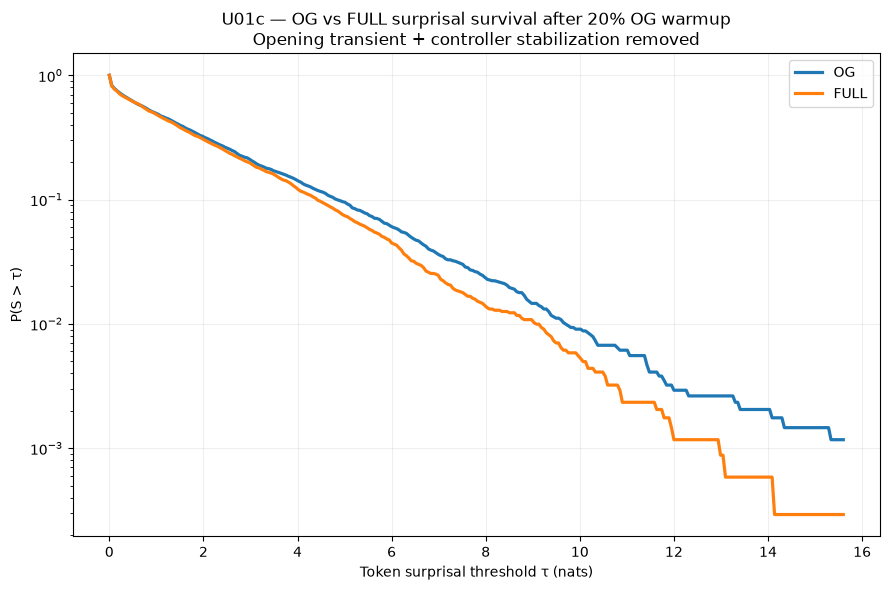

,relative_bin,bin_midpoint,tau,n_cases,OG_tail_rate,FULL_tail_rate,FULL_minus_OG
0,1-32,16.5,3,20,0.203125,0.217188,0.014063
1,1-32,16.5,4,20,0.128125,0.132812,0.004688
2,1-32,16.5,6,20,0.050000,0.054688,0.004687
3,1-32,16.5,8,20,0.015625,0.015625,0.000000
4,129-192,160.5,3,6,0.164062,0.190104,0.026042
5,129-192,160.5,4,6,0.111979,0.117188,0.005208
6,129-192,160.5,6,6,0.041667,0.033854,-0.007812
7,129-192,160.5,8,6,0.013021,0.015625,0.002604
8,33-64,48.5,3,20,0.218750,0.229687,0.010937
9,33-64,48.5,4,20,0.142187,0.145313,0.003125


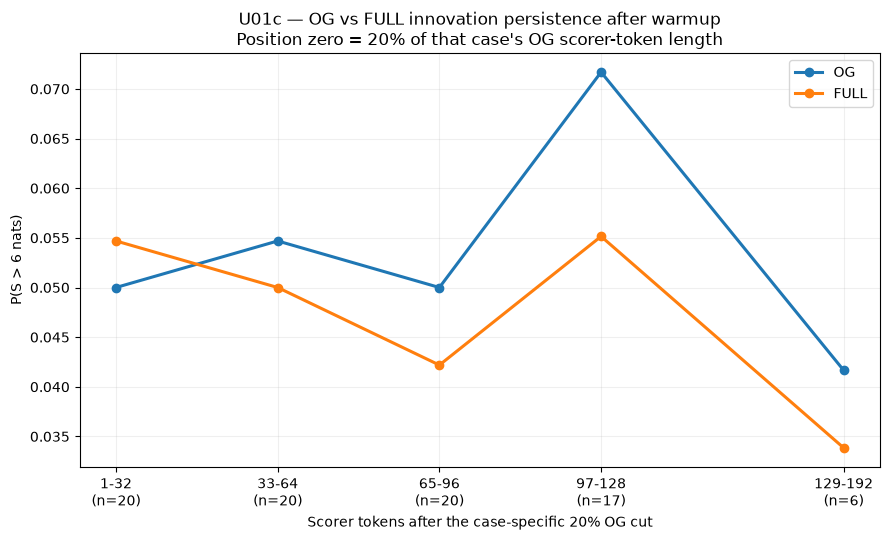


Saved post-20% OG/FULL diagnostics to: ../results/causal/U01c_alpha_information_flow


In [6]:
# ============================================================
# U01c — OG vs FULL AFTER first 20% of OG scorer tokens
#
# Motivation:
#   Unique control begins at ~15% of the expected OG trajectory.
#   Discard the first 20% of OG scorer tokens to remove:
#       - the high-surprisal opening transient
#       - the controller warmup period
#       - ~5% extra stabilization margin
#
# For each case:
#
#     cut_i = ceil(0.20 * OG_total_scorer_tokens)
#
# We apply that SAME absolute cut position to OG and FULL, then
# compare only the matched suffix available in both texts.
#
# Requires the previous OG/FULL cell:
#   paired_losses
#   pair_meta
#   panel
# ============================================================

POST_CUT_FRACTION = 0.20
TAILS = [2, 3, 4, 5, 6, 8, 10]

meta_lookup = (
    pair_meta
    .set_index("case_id")
)

post20 = {}
post20_meta = []

for cid in panel["case_id"].astype(str):

    og = paired_losses[(cid, "OG")]
    fu = paired_losses[(cid, "FULL")]

    # Total OG scorer-token length, not merely the truncated 256-token window.
    og_total = int(
        meta_lookup.loc[
            cid,
            "OG_total_tokens"
        ]
    )

    # Loss index 0 predicts scorer token position 1.
    # If cut_token = 40, retain positions 41 onward -> loss index 40 onward.
    cut_token = int(
        np.ceil(
            POST_CUT_FRACTION * og_total
        )
    )

    m = min(
        len(og),
        len(fu),
    )

    if cut_token >= m:
        continue

    og_post = og[cut_token:m]
    fu_post = fu[cut_token:m]

    assert len(og_post) == len(fu_post)

    post20[(cid, "OG")] = og_post
    post20[(cid, "FULL")] = fu_post

    post20_meta.append({
        "case_id": cid,
        "OG_total_tokens": og_total,
        "cut_token_20pct": cut_token,
        "matched_end_token": m,
        "post_cut_positions": len(og_post),
    })


post20_meta = pd.DataFrame(post20_meta)

print(
    "Cases surviving 20% cut:",
    len(post20_meta),
    "/",
    len(panel),
)

display(post20_meta)


# ------------------------------------------------------------
# 1. Aggregate suffix distributions.
# ------------------------------------------------------------

valid_cases = (
    post20_meta["case_id"]
    .astype(str)
    .tolist()
)

og_post = np.concatenate([
    post20[(cid, "OG")]
    for cid in valid_cases
])

full_post = np.concatenate([
    post20[(cid, "FULL")]
    for cid in valid_cases
])


def _summary(x):
    x = np.asarray(x, float)

    return {
        "n": len(x),
        "mean": np.mean(x),
        "median": np.median(x),
        "q75": np.quantile(x, .75),
        "q90": np.quantile(x, .90),
        "q95": np.quantile(x, .95),
        "q99": np.quantile(x, .99),
    }


post20_summary = pd.DataFrame([
    {
        "condition": "OG",
        **_summary(og_post),
    },
    {
        "condition": "FULL",
        **_summary(full_post),
    },
]).set_index("condition")

print("\nPost-20% surprisal distribution:")
display(post20_summary)


# ------------------------------------------------------------
# 2. Tail frequency vs conditional magnitude.
# ------------------------------------------------------------

tail_rows = []

for condition, x in [
    ("OG", og_post),
    ("FULL", full_post),
]:

    for tau in TAILS:

        mask = x > tau

        tail_rows.append({
            "condition": condition,
            "tau": tau,

            "P_S_gt_tau":
                float(mask.mean()),

            "E_S_given_tail":
                float(
                    x[mask].mean()
                    if mask.any()
                    else np.nan
                ),

            "fraction_total_surprisal_from_tail":
                float(
                    x[mask].sum() / x.sum()
                    if x.sum() > 0
                    else np.nan
                ),
        })


post20_tail = pd.DataFrame(
    tail_rows
)

print("\nPost-20% tail frequency / magnitude:")

display(
    post20_tail.pivot(
        index="tau",
        columns="condition",
        values=[
            "P_S_gt_tau",
            "E_S_given_tail",
            "fraction_total_surprisal_from_tail",
        ],
    )
)


# ------------------------------------------------------------
# 3. Paired case-level innovation-rate difference.
# ------------------------------------------------------------

case_rows = []

for cid in valid_cases:

    og = post20[(cid, "OG")]
    fu = post20[(cid, "FULL")]

    for tau in TAILS:

        case_rows.append({
            "case_id": cid,
            "tau": tau,

            "OG":
                float(
                    np.mean(og > tau)
                ),

            "FULL":
                float(
                    np.mean(fu > tau)
                ),
        })


post20_case_tail = pd.DataFrame(
    case_rows
)

post20_case_tail[
    "FULL_minus_OG"
] = (
    post20_case_tail["FULL"]
    - post20_case_tail["OG"]
)


# Matched-case bootstrap.
rng = np.random.default_rng(20260916)
N_BOOT = 5000

boot_rows = []

for tau in TAILS:

    z = post20_case_tail[
        post20_case_tail["tau"].eq(tau)
    ]

    d = (
        z["FULL_minus_OG"]
        .to_numpy(float)
    )

    n = len(d)

    idx = rng.integers(
        0,
        n,
        size=(N_BOOT, n),
    )

    bm = d[idx].mean(axis=1)

    boot_rows.append({
        "tau": tau,
        "n_cases": n,

        "OG_tail_rate":
            z["OG"].mean(),

        "FULL_tail_rate":
            z["FULL"].mean(),

        "FULL_minus_OG":
            d.mean(),

        "median_delta":
            np.median(d),

        "ci_low":
            np.quantile(bm, .025),

        "ci_high":
            np.quantile(bm, .975),

        "fraction_cases_FULL_gt_OG":
            np.mean(d > 0),
    })


post20_boot = pd.DataFrame(
    boot_rows
)

print("\nPaired post-20% innovation-rate shift:")
display(post20_boot)


# ------------------------------------------------------------
# 4. Survival curve AFTER the 20% OG cut.
# ------------------------------------------------------------

xmax = min(
    20.0,
    max(
        np.quantile(og_post, .999),
        np.quantile(full_post, .999),
    ),
)

taus = np.linspace(
    0,
    xmax,
    300,
)

og_survival = np.array([
    np.mean(og_post > tau)
    for tau in taus
])

full_survival = np.array([
    np.mean(full_post > tau)
    for tau in taus
])

fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.plot(
    taus,
    og_survival,
    linewidth=2.3,
    label="OG",
)

ax.plot(
    taus,
    full_survival,
    linewidth=2.3,
    label="FULL",
)

ax.set_yscale("log")

ax.set_xlabel(
    "Token surprisal threshold τ (nats)"
)

ax.set_ylabel(
    "P(S > τ)"
)

ax.set_title(
    "U01c — OG vs FULL surprisal survival after 20% OG warmup\n"
    "Opening transient + controller stabilization removed"
)

ax.grid(alpha=.2)
ax.legend()

fig.tight_layout()

fig.savefig(
    OUT / "OG_FULL_post20pct_surprisal_survival.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# 5. Innovation persistence RELATIVE TO THE 20% CUT.
#
# x=1 means first scorer token after the case-specific 20% OG cut.
# ------------------------------------------------------------

RELATIVE_BINS = [
    (1, 32),
    (33, 64),
    (65, 96),
    (97, 128),
    (129, 192),
]

POSITION_TAILS = [3, 4, 6, 8]

relative_rows = []

for cid in valid_cases:

    og = post20[(cid, "OG")]
    fu = post20[(cid, "FULL")]

    m = len(og)

    for lo, hi in RELATIVE_BINS:

        if m < hi:
            continue

        # relative position 1 -> array index 0
        sl = slice(
            lo - 1,
            hi,
        )

        for tau in POSITION_TAILS:

            relative_rows.append({
                "case_id": cid,

                "relative_bin":
                    f"{lo}-{hi}",

                "bin_midpoint":
                    (lo + hi) / 2,

                "tau": tau,

                "OG_tail_rate":
                    float(
                        np.mean(
                            og[sl] > tau
                        )
                    ),

                "FULL_tail_rate":
                    float(
                        np.mean(
                            fu[sl] > tau
                        )
                    ),
            })


post20_position = pd.DataFrame(
    relative_rows
)

post20_position_summary = (
    post20_position
    .groupby(
        [
            "relative_bin",
            "bin_midpoint",
            "tau",
        ],
        as_index=False,
    )
    .agg(
        n_cases=(
            "case_id",
            "nunique",
        ),

        OG_tail_rate=(
            "OG_tail_rate",
            "mean",
        ),

        FULL_tail_rate=(
            "FULL_tail_rate",
            "mean",
        ),
    )
)

post20_position_summary[
    "FULL_minus_OG"
] = (
    post20_position_summary[
        "FULL_tail_rate"
    ]
    - post20_position_summary[
        "OG_tail_rate"
    ]
)

display(
    post20_position_summary
)


# ------------------------------------------------------------
# 6. Plot persistence for tau = 6.
# ------------------------------------------------------------

TAU_PLOT = 6

z = (
    post20_position_summary[
        post20_position_summary[
            "tau"
        ].eq(TAU_PLOT)
    ]
    .sort_values("bin_midpoint")
)

fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

ax.plot(
    z["bin_midpoint"],
    z["OG_tail_rate"],
    marker="o",
    linewidth=2.2,
    label="OG",
)

ax.plot(
    z["bin_midpoint"],
    z["FULL_tail_rate"],
    marker="o",
    linewidth=2.2,
    label="FULL",
)

ax.set_xticks(
    z["bin_midpoint"],
    [
        f"{b}\n(n={n})"
        for b, n in zip(
            z["relative_bin"],
            z["n_cases"],
        )
    ],
)

ax.set_xlabel(
    "Scorer tokens after the case-specific 20% OG cut"
)

ax.set_ylabel(
    f"P(S > {TAU_PLOT} nats)"
)

ax.set_title(
    "U01c — OG vs FULL innovation persistence after warmup\n"
    "Position zero = 20% of that case's OG scorer-token length"
)

ax.grid(alpha=.2)
ax.legend()

fig.tight_layout()

fig.savefig(
    OUT / "OG_FULL_post20pct_tail_persistence.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

post20_meta.to_csv(
    OUT / "OG_FULL_post20pct_support.csv",
    index=False,
)

post20_summary.to_csv(
    OUT / "OG_FULL_post20pct_distribution.csv",
)

post20_tail.to_csv(
    OUT / "OG_FULL_post20pct_tail_summary.csv",
    index=False,
)

post20_boot.to_csv(
    OUT / "OG_FULL_post20pct_tail_bootstrap.csv",
    index=False,
)

post20_position_summary.to_csv(
    OUT / "OG_FULL_post20pct_tail_by_relative_position.csv",
    index=False,
)

print(
    "\nSaved post-20% OG/FULL diagnostics to:",
    OUT,
)